# Comparación de 4 modelos OCR para leer facturas (Dai · PocketPal)

Este cuaderno toma el **dataset limpio de facturas** (el zip que sale de `dataset_facturas.ipynb`) y compara cuatro modelos OCR: **Tesseract, EasyOCR, docTR y PaddleOCR**.

Para cada modelo mide:

1. **Monto:** si leyó bien el total de la factura.
2. **Fecha:** si leyó bien la fecha.
3. **Categoría:** qué tan bien un clasificador entrenado con el texto que leyó ese OCR adivina la categoría.
4. **Motivo:** si el motivo que Dai sugiere (copiado de la factura de entrenamiento más parecida) comparte palabras clave con el que escribió la persona.
5. **Facturas sin corrección:** cuántas facturas quedarían bien en los cuatro campos, es decir, las que el usuario no tendría que corregir en la pantalla “Confirmar”.
6. **Tiempo** por factura.

Al final arma una **tabla de decisión** para escoger el modelo con datos.

### Por qué esta versión no se cae

| Problema de la versión anterior | Cómo se resuelve aquí |
|---|---|
| Los 4 modelos se instalaban en el mismo entorno y sus librerías chocaban (numpy, opencv, torch), dañando el entorno de Colab. | **Cada modelo se instala en su propio entorno aislado.** El entorno principal del cuaderno no se toca. |
| Los 4 modelos quedaban cargados en memoria al mismo tiempo y Colab se quedaba sin RAM. | **Cada modelo corre en un proceso aparte, uno por uno.** Al terminar, libera toda su memoria. |
| Si Colab se desconectaba, había que empezar de cero. | **Los resultados se guardan a medida que avanza.** Si algo se cae, vuelves a correr la misma celda y retoma donde iba. |
| Si un modelo fallaba, se perdía todo. | Si un modelo falla, el cuaderno lo informa y **sigue con los demás**. |
| PaddleOCR 3.3 tiene un error conocido en CPU (`ConvertPirAttribute2RuntimeAttribute`). | Se instala **PaddlePaddle 3.2.2**, y si aun así falla la aceleración de CPU, se reintenta sin ella automáticamente. |

### Mejoras para que la comparación sea justa
- **Mismas reglas para los 4 modelos.** Antes de buscar el monto se corrigen los errores típicos del OCR en las cifras: `249 900` → `249.900`, `85 . 000` → `85.000`, `1l.000` → `11.000`. Sin esto, un modelo que lee bien pero separa los números con espacios (como EasyOCR) salía castigado injustamente.
- Las líneas de **teléfono** (`TEL`, `celular`, `WhatsApp`) se ignoran al buscar el monto, para no confundir un número de teléfono con el total.
- El mejor clasificador se escoge con **validación cruzada sobre el entrenamiento**, nunca mirando las facturas de prueba.

### Antes de empezar: funciona en VS Code y en Colab

**En VS Code (en tu computador)**
1. Ten instalado **Python 3.12** y en VS Code las extensiones **Python** y **Jupyter**.
2. Instala el programa **Tesseract**. En Windows usa el instalador de UB Mannheim y marca **Spanish** en los idiomas. En Mac escribe `brew install tesseract tesseract-lang`.
3. Pon este cuaderno y `dataset_facturas.zip` en **una carpeta de ruta corta y fuera de OneDrive**, por ejemplo `C:\ocr`.
4. Abre la carpeta en VS Code, abre el cuaderno y en **Select Kernel** crea o escoge un entorno con Python 3.12.
5. Corre las celdas en orden. La primera vez descarga unas librerías grandes (unos 3 GB) y tarda un rato.

**En Colab**
- **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU T4.** Acelera EasyOCR y docTR.
- Deja `GUARDAR_EN_DRIVE = True` para no perder lo que ya leyó cada modelo si Colab se reinicia.

En los dos casos, si algo se interrumpe, vuelves a correr la misma celda y sigue donde iba.

In [ ]:
# ===================== CONFIGURACIÓN (puedes cambiar estos valores) =====================
MODELOS = ["tesseract", "easyocr", "doctr", "paddleocr"]   # quita uno de la lista si no lo quieres correr
LADO_MAX = 2000        # lado largo (px) de la copia que se le pasa al OCR. Las fotos originales no se tocan
MAX_FACTURAS = None    # pon 10 para una prueba rápida; None = todas las facturas
TEST_SIZE = 0.25       # proporción de facturas reservadas para la prueba
SEMILLA = 42           # con la misma semilla, la separación entrenamiento/prueba es siempre igual

GUARDAR_EN_DRIVE = True   # solo en Colab: guarda el avance en Google Drive. En VS Code no hace nada
RUTA_ZIP = ""             # en VS Code: déjalo vacío si dataset_facturas.zip está en la misma carpeta del cuaderno
                          # o pon la ruta completa, ej. r"C:\ocr\dataset_facturas.zip"
EMPEZAR_DE_CERO = False   # True = borra lo que ya habían leído los modelos (úsalo si cambias LADO_MAX o el dataset)

## 1. Cargar el dataset de facturas
Si ya lo habías subido antes en esta misma sesión (o en Drive), no te lo vuelve a pedir.

In [ ]:
import os, sys, re, json, time, shutil, zipfile, subprocess, unicodedata, warnings, glob, importlib.util
import datetime as dt

# En VS Code puede faltar alguna librería básica: se instala sola en el entorno del cuaderno
NECESARIAS = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
              "sklearn": "scikit-learn", "PIL": "pillow", "virtualenv": "virtualenv"}
faltan = [paquete for modulo, paquete in NECESARIAS.items() if importlib.util.find_spec(modulo) is None]
if faltan:
    print("Instalando librerías básicas:", " ".join(faltan))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

EN_KAGGLE = bool(os.environ.get("KAGGLE_KERNEL_RUN_TYPE")) or os.path.exists("/kaggle/working")
# Ojo: Kaggle también trae instalada la librería google.colab, por eso se revisa que sea Colab de verdad
EN_COLAB = os.path.exists("/var/colab/hostname") and not EN_KAGGLE
if EN_COLAB:
    from google.colab import files, drive
EN_NUBE = EN_COLAB or EN_KAGGLE      # Colab y Kaggle ya traen torch instalado
if EN_KAGGLE:
    os.chdir("/kaggle/working")

if EN_COLAB and GUARDAR_EN_DRIVE:
    drive.mount("/content/drive")
    TRABAJO = "/content/drive/MyDrive/comparacion_ocr_facturas"
elif EN_KAGGLE:
    TRABAJO = "/kaggle/working/comparacion_ocr_facturas"
else:
    TRABAJO = os.path.abspath("comparacion_ocr_facturas")
if EMPEZAR_DE_CERO:
    shutil.rmtree(TRABAJO, ignore_errors=True)
DATASET = os.path.join(TRABAJO, "dataset")
CACHE = os.path.join(TRABAJO, "lecturas_ocr")        # lo que va leyendo cada modelo
RESULTADOS = os.path.join(TRABAJO, "resultados")
LOCAL = "/content/ocr_local" if EN_COLAB else ("/tmp/ocr_local" if EN_KAGGLE else os.path.abspath("ocr_local"))   # entornos y copias de imágenes (rápido, fuera de Drive)
for d in (TRABAJO, CACHE, RESULTADOS, LOCAL):
    os.makedirs(d, exist_ok=True)

def buscar_csv(raiz):
    for r, _, fs in os.walk(raiz):
        if "facturas.csv" in fs:
            return os.path.join(r, "facturas.csv")
    return None

csv_ruta = buscar_csv(DATASET)
if csv_ruta is None and EN_KAGGLE:
    csv_ruta = buscar_csv("/kaggle/input")   # Kaggle descomprime solo el zip que subes como "Input"
if csv_ruta is None:
    if RUTA_ZIP:
        nombre_zip = RUTA_ZIP
    elif EN_COLAB:
        print("Sube el dataset_facturas.zip (el que descargaste de dataset_facturas.ipynb)")
        subido = files.upload()
        nombre_zip = next(n for n in subido if n.lower().endswith(".zip"))
    else:
        candidatos = sorted(glob.glob("dataset_facturas*.zip") + glob.glob("/kaggle/input/**/*.zip", recursive=True))
        if not candidatos:
            raise FileNotFoundError("No encontré el dataset. Copia dataset_facturas.zip en la misma carpeta "
                                    "de este cuaderno, o escribe su ruta completa en RUTA_ZIP.")
        nombre_zip = candidatos[0]
        print("Usando", nombre_zip)
    with zipfile.ZipFile(nombre_zip) as z:
        z.extractall(DATASET)
    csv_ruta = buscar_csv(DATASET)
    assert csv_ruta, "El zip no trae facturas.csv: usa el zip que genera dataset_facturas.ipynb"
else:
    print("Dataset encontrado, no hace falta subirlo de nuevo.")

RAIZ = os.path.dirname(csv_ruta)
df = pd.read_csv(csv_ruta)
# Unifica cómo está escrita la categoría: " alimentación" y "Alimentación" deben contar como la misma
df["categoria"] = (df["categoria"].fillna("Sin categoría").astype(str).str.strip()
                   .str.replace(r"\s+", " ", regex=True).str.capitalize())
df["fotos"] = df["foto"].astype(str).str.split(";")
if MAX_FACTURAS:
    df = df.head(MAX_FACTURAS).copy()
df = df.reset_index(drop=True)
print(f"Facturas cargadas: {len(df)}")
print(df["categoria"].value_counts().to_string())

Instalando librerías básicas: virtualenv
Mounted at /content/drive
Dataset encontrado, no hace falta subirlo de nuevo.
Facturas cargadas: 143
categoria
Supermercado                 32
Transporte                   26
Servicios                    18
Entretenimiento              17
Restaurantes y domicilios    12
Otros                        11
Salud                        11
Educación                     8
Ropa y accesorios             4
Hogar                         4


## 2. Separar entrenamiento y prueba
Se hace **una sola vez** y con semilla fija. Cada categoría queda repartida en las dos partes.
Las reglas de monto y fecha no se entrenan, pero el clasificador de categoría sí: por eso se evalúa solo con las facturas de prueba.

split                      entrenamiento  prueba
categoria                                       
Educación                              6       2
Entretenimiento                       13       4
Hogar                                  3       1
Otros                                  8       3
Restaurantes y domicilios              9       3
Ropa y accesorios                      3       1
Salud                                  8       3
Servicios                             14       4
Supermercado                          24       8
Transporte                            19       7

AVISO: estas categorías tienen menos de 5 facturas y el clasificador casi no puede aprenderlas: Ropa y accesorios, Hogar


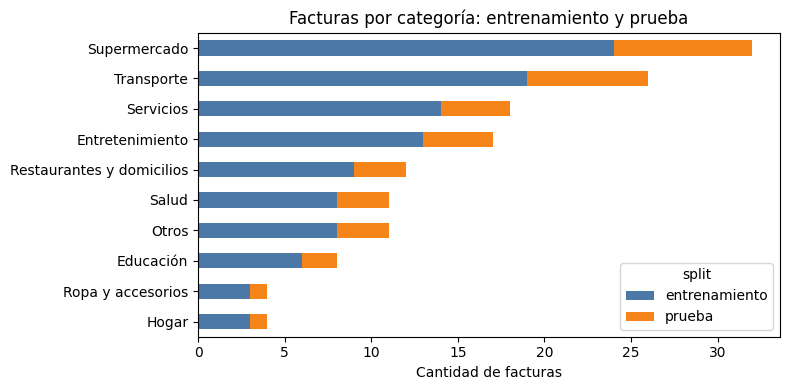

In [ ]:
from sklearn.model_selection import train_test_split

conteo = df["categoria"].value_counts()
con_dos = conteo[conteo >= 2].index          # una categoría con 1 sola factura no se puede repartir
df["split"] = "entrenamiento"
candidatas = df[df["categoria"].isin(con_dos)].index
try:
    _, idx_prueba = train_test_split(candidatas, test_size=TEST_SIZE,
                                     stratify=df.loc[candidatas, "categoria"], random_state=SEMILLA)
except ValueError:
    _, idx_prueba = train_test_split(candidatas, test_size=TEST_SIZE, random_state=SEMILLA)
df.loc[idx_prueba, "split"] = "prueba"

tab = pd.crosstab(df["categoria"], df["split"]).reindex(columns=["entrenamiento", "prueba"], fill_value=0)
print(tab.to_string())
pocas = [c for c, n in conteo.items() if n < 5]
if pocas:
    print("\nAVISO: estas categorías tienen menos de 5 facturas y el clasificador casi no puede aprenderlas:", ", ".join(pocas))

tab = tab.loc[tab.sum(axis=1).sort_values().index]
ax = tab.plot(kind="barh", stacked=True, figsize=(8, 4), color=["#4C78A8", "#F58518"])
ax.set_title("Facturas por categoría: entrenamiento y prueba")
ax.set_xlabel("Cantidad de facturas")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(os.path.join(RESULTADOS, "grafica_categorias_split.png"), dpi=150)
plt.show()

## 3. Preparar las imágenes
Se hace una copia JPG de cada foto, con el lado largo de máximo `LADO_MAX` píxeles. **Los cuatro modelos leen exactamente las mismas copias**, así la comparación es justa.

In [ ]:
from PIL import Image, ImageOps

hay_heic = any(f.lower().endswith((".heic", ".heif")) for fs in df["fotos"] for f in fs)
if hay_heic:
    try:
        import pillow_heif
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pillow-heif"], check=False)
        import pillow_heif
    pillow_heif.register_heif_opener()

IMG_OCR = os.path.join(LOCAL, f"imagenes_ocr_{LADO_MAX}")
os.makedirs(IMG_OCR, exist_ok=True)

def preparar(nombre):
    destino = os.path.join(IMG_OCR, os.path.splitext(nombre)[0] + ".jpg")
    if not os.path.exists(destino):
        img = ImageOps.exif_transpose(Image.open(os.path.join(RAIZ, "imagenes", nombre))).convert("RGB")
        if LADO_MAX and max(img.size) > LADO_MAX:
            img.thumbnail((LADO_MAX, LADO_MAX), Image.LANCZOS)
        img.save(destino, quality=95)
    return destino

manifiesto, sin_foto = [], 0
for i, fotos in enumerate(df["fotos"]):
    rutas = []
    for f in fotos:
        try:
            rutas.append(preparar(f))
        except Exception as e:
            sin_foto += 1
            print(f"No se pudo abrir {f}: {str(e)[:80]}")
    manifiesto.append({"id": i, "imagenes": rutas})
MANIFIESTO = os.path.join(LOCAL, "manifiesto.json")
with open(MANIFIESTO, "w", encoding="utf-8") as f:
    json.dump(manifiesto, f)
print(f"Imágenes listas: {sum(len(m['imagenes']) for m in manifiesto)} (para {len(manifiesto)} facturas). Fallaron: {sin_foto}")

Imágenes listas: 173 (para 143 facturas). Fallaron: 0


## 4. Instalar cada modelo en su propio entorno
Cada modelo queda en una carpeta aparte (`ocr_local/entornos`) con sus propias librerías. Si uno no se instala, los demás siguen.
La primera vez tarda bastante, porque EasyOCR y docTR necesitan PyTorch y PaddleOCR necesita PaddlePaddle. Si vuelves a correr la celda, salta los que ya están listos.

In [ ]:
ENTORNOS = os.path.join(LOCAL, "entornos")
os.makedirs(ENTORNOS, exist_ok=True)

WINDOWS = os.name == "nt"

def sh(args):
    r = subprocess.run(args, capture_output=True, text=True, encoding="utf-8", errors="replace")
    return r.returncode, (r.stdout or "") + (r.stderr or "")

# usa_sistema=True: en Colab el entorno usa el torch que ya trae Colab (no lo vuelve a descargar).
# En VS Code cada entorno instala lo suyo. En Linux se pide primero el torch solo-CPU, que pesa mucho menos.
TORCH_CPU = (["torch torchvision --index-url https://download.pytorch.org/whl/cpu"]
             if (not EN_NUBE and sys.platform.startswith("linux")) else [])
# PaddleOCR va totalmente aislado porque es el que más choca con las demás librerías.
# "pip" es una lista de opciones: si la primera falla, se intenta la siguiente.
# PaddlePaddle se fija en 3.2.2 porque la 3.3 tiene un error conocido en CPU
# ("ConvertPirAttribute2RuntimeAttribute not support"); si no existe para tu Python, usa la más nueva.
REQUISITOS = {
    "tesseract": {"usa_sistema": True,  "antes": [], "pip": ["pytesseract pillow"],
                  "prueba": "import pytesseract; print('tesseract ok')"},
    "easyocr":   {"usa_sistema": True,  "antes": TORCH_CPU, "pip": ["easyocr"],
                  "prueba": "import easyocr; print('easyocr ok')"},
    "doctr":     {"usa_sistema": True,  "antes": TORCH_CPU, "pip": ["python-doctr"],
                  "prueba": "from doctr.models import ocr_predictor; print('doctr ok')"},
    "paddleocr": {"usa_sistema": False, "antes": [], "pip": ["paddlepaddle==3.2.2 paddleocr", "paddlepaddle paddleocr"],
                  "prueba": "from paddleocr import PaddleOCR; print('paddleocr ok')"},
}

if sh([sys.executable, "-m", "virtualenv", "--version"])[0] != 0:
    sh([sys.executable, "-m", "pip", "install", "-q", "virtualenv"])

# Tesseract es un programa aparte (no una librería de Python): hay que encontrarlo en el computador
def buscar_tesseract():
    candidatos = [shutil.which("tesseract"),
                  r"C:\Program Files\Tesseract-OCR\tesseract.exe",
                  r"C:\Program Files (x86)\Tesseract-OCR\tesseract.exe",
                  os.path.join(os.environ.get("LOCALAPPDATA", ""), "Programs", "Tesseract-OCR", "tesseract.exe"),
                  "/opt/homebrew/bin/tesseract", "/usr/local/bin/tesseract", "/usr/bin/tesseract"]
    return next((c for c in candidatos if c and os.path.exists(c)), None)

TESSERACT_CMD = None
if "tesseract" in MODELOS:
    TESSERACT_CMD = buscar_tesseract()
    if TESSERACT_CMD is None and sys.platform.startswith("linux") and shutil.which("apt-get"):
        print("Instalando el programa Tesseract (con español)...")
        sudo = "" if (hasattr(os, "geteuid") and os.geteuid() == 0) else "sudo -n "
        sh(["bash", "-c", f"{sudo}apt-get -qq update && {sudo}apt-get -qq install -y tesseract-ocr tesseract-ocr-spa"])
        TESSERACT_CMD = buscar_tesseract()
    if TESSERACT_CMD is None:
        print("AVISO: no encontré el programa Tesseract en este computador; Tesseract se salta por ahora.\n"
              "  Windows: instálalo desde https://github.com/UB-Mannheim/tesseract/wiki (marca Spanish en los idiomas)\n"
              "  Mac: en la Terminal escribe  brew install tesseract tesseract-lang\n"
              "  Después vuelve a correr esta celda.\n")
    else:
        print("Tesseract encontrado en:", TESSERACT_CMD)
os.environ["TESSERACT_CMD"] = TESSERACT_CMD or ""

def python_de(motor):
    if WINDOWS:
        return os.path.join(ENTORNOS, motor, "Scripts", "python.exe")
    return os.path.join(ENTORNOS, motor, "bin", "python")

def instalar(motor):
    req = REQUISITOS[motor]
    if motor == "tesseract" and not TESSERACT_CMD:
        return False
    destino = os.path.join(ENTORNOS, motor)
    marca = os.path.join(destino, ".listo")
    if os.path.exists(marca):
        print(f"{motor}: ya estaba instalado")
        return True
    shutil.rmtree(destino, ignore_errors=True)
    t0 = time.time()
    print(f"{motor}: instalando...", end=" ", flush=True)
    flag = ["--system-site-packages"] if (req["usa_sistema"] and EN_NUBE) else []
    c, out = sh([sys.executable, "-m", "virtualenv", "-q", *flag, destino])
    if c != 0:
        print("no se pudo crear el entorno\n" + out[-800:])
        return False
    pip = [python_de(motor), "-m", "pip", "install", "-q", "--disable-pip-version-check"]
    for paso in req["antes"]:      # paso previo opcional (torch solo-CPU); si falla, se sigue normal
        sh(pip + paso.split())
    for opcion in req["pip"]:      # opciones en orden: si la primera falla, se intenta la siguiente
        c, out = sh(pip + opcion.split())
        if c == 0:
            break
    if c != 0:
        print("falló la instalación\n" + out[-1500:])
        return False
    c, out = sh([python_de(motor), "-c", req["prueba"]])
    if c != 0:
        print("se instaló pero no carga\n" + out[-1500:])
        return False
    open(marca, "w").close()
    print(f"listo ({time.time() - t0:.0f} s)")
    return True

INSTALADOS = [m for m in MODELOS if instalar(m)]
print("\nModelos listos para correr:", INSTALADOS)

Tesseract encontrado en: /usr/bin/tesseract
tesseract: instalando... listo (5 s)
easyocr: instalando... listo (24 s)
doctr: instalando... listo (19 s)
paddleocr: instalando... listo (84 s)

Modelos listos para correr: ['tesseract', 'easyocr', 'doctr', 'paddleocr']


## 5. Programa que lee las facturas con un modelo
Esta celda solo crea el archivo `ocr_worker.py`. Cada modelo lo ejecuta por separado en la siguiente celda.

Detalle importante para que la comparación sea justa: EasyOCR y PaddleOCR devuelven **pedacitos de texto sueltos**. Aquí se **reconstruyen las líneas** según su posición en la foto, así palabras como “TOTAL” y “$45.000” quedan en la misma línea, igual que en Tesseract y docTR.

In [ ]:
WORKER = os.path.join(LOCAL, "ocr_worker.py")
with open(WORKER, "w", encoding="utf-8") as f:
    f.write(r"""
import sys, os, json, time, warnings
warnings.filterwarnings("ignore")
motor, manifiesto, salida = sys.argv[1], sys.argv[2], sys.argv[3]
items = json.load(open(manifiesto, encoding="utf-8"))

hechos = {}
if os.path.exists(salida):
    try:
        hechos = json.load(open(salida, encoding="utf-8"))["resultados"]
    except Exception:
        hechos = {}
pendientes = [it for it in items if str(it["id"]) not in hechos]
if not pendientes:
    print(f"{motor}: ya estaba completo", flush=True)
    sys.exit(0)

def guardar(info):
    tmp = salida + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump({"motor": motor, "info": info, "resultados": hechos}, f, ensure_ascii=False)
    os.replace(tmp, salida)

def agrupar_lineas(cajas):
    # cajas: (x0, y0, x1, y1, texto). Junta en una línea las que están a la misma altura.
    cajas = sorted([c for c in cajas if str(c[4]).strip()], key=lambda c: (c[1] + c[3]) / 2)
    lineas = []
    for c in cajas:
        cy, h = (c[1] + c[3]) / 2, max(1.0, c[3] - c[1])
        if lineas and abs(cy - lineas[-1]["cy"]) < 0.5 * max(h, lineas[-1]["h"]):
            L = lineas[-1]
            L["cajas"].append(c)
            L["cy"] = sum((k[1] + k[3]) / 2 for k in L["cajas"]) / len(L["cajas"])
            L["h"] = max(L["h"], h)
        else:
            lineas.append({"cy": cy, "h": h, "cajas": [c]})
    return "\n".join(" ".join(str(k[4]) for k in sorted(L["cajas"], key=lambda k: k[0])) for L in lineas)

def hay_gpu():
    try:
        import torch
        return torch.cuda.is_available()
    except Exception:
        return False

t_carga = time.time()
if motor == "tesseract":
    import pytesseract
    from PIL import Image
    if os.environ.get("TESSERACT_CMD"):
        pytesseract.pytesseract.tesseract_cmd = os.environ["TESSERACT_CMD"]
    idioma = "spa" if "spa" in pytesseract.get_languages() else "eng"
    dispositivo = f"CPU (idioma {idioma})"
    def leer(p):
        return pytesseract.image_to_string(Image.open(p), lang=idioma, config="--psm 6")

elif motor == "easyocr":
    import easyocr
    g = hay_gpu()
    dispositivo = "GPU" if g else "CPU"
    lector = easyocr.Reader(["es", "en"], gpu=g, verbose=False)
    def leer(p):
        cajas = []
        for caja, texto, _ in lector.readtext(p, detail=1, paragraph=False):
            xs, ys = [float(q[0]) for q in caja], [float(q[1]) for q in caja]
            cajas.append((min(xs), min(ys), max(xs), max(ys), texto))
        return agrupar_lineas(cajas)

elif motor == "doctr":
    from doctr.models import ocr_predictor
    from doctr.io import DocumentFile
    g = hay_gpu()
    dispositivo = "GPU" if g else "CPU"
    modelo = ocr_predictor(pretrained=True)
    if g:
        modelo = modelo.cuda()
    def leer(p):
        return modelo(DocumentFile.from_images([p])).render()

elif motor == "paddleocr":
    os.environ.setdefault("PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK", "True")
    from paddleocr import PaddleOCR
    dispositivo = "CPU"
    def crear(mkldnn):
        # lang="es": PaddleOCR escoge solo los modelos de detección y lectura para español
        return PaddleOCR(lang="es", use_doc_orientation_classify=False, use_doc_unwarping=False,
                         use_textline_orientation=True, device="cpu", enable_mkldnn=mkldnn)
    try:   # PaddleOCR 3.x
        lector = crear(True)
        v3 = True
        try:   # si la aceleración de CPU (oneDNN) falla en esta máquina, se apaga y se sigue
            primera = next(it["imagenes"][0] for it in pendientes if it["imagenes"])
            list(lector.predict(primera))
        except Exception as e:
            print(f"paddleocr: oneDNN falló ({str(e)[:80]}...), se reintenta sin oneDNN", flush=True)
            lector = crear(False)
            dispositivo = "CPU sin oneDNN"
    except TypeError:   # PaddleOCR 2.x
        lector = PaddleOCR(lang="es", use_angle_cls=True, show_log=False)
        v3 = False
    def leer(p):
        cajas = []
        if v3:
            for r in lector.predict(p):
                textos = list(r["rec_texts"])
                try:
                    boxes = [list(map(float, b)) for b in r["rec_boxes"]]
                except Exception:
                    boxes = [[min(q[0] for q in pl), min(q[1] for q in pl), max(q[0] for q in pl), max(q[1] for q in pl)]
                             for pl in r["rec_polys"]]
                cajas += [(b[0], b[1], b[2], b[3], t) for b, t in zip(boxes, textos)]
        else:
            for pagina in lector.ocr(p, cls=True) or []:
                for caja, (texto, _) in pagina or []:
                    xs, ys = [q[0] for q in caja], [q[1] for q in caja]
                    cajas.append((min(xs), min(ys), max(xs), max(ys), texto))
        return agrupar_lineas(cajas)
else:
    raise SystemExit(f"Modelo desconocido: {motor}")

info = {"dispositivo": dispositivo, "segundos_carga": round(time.time() - t_carga, 1)}
print(f"{motor}: modelo cargado en {info['segundos_carga']} s ({dispositivo}). Facturas pendientes: {len(pendientes)}", flush=True)

# Calentamiento: la primera lectura siempre es más lenta y no debe contar en el tiempo.
# Además sirve de prueba: si el modelo no logra leer ninguna de las 3 primeras fotos, algo está mal
# instalado y es mejor detenerse con un mensaje claro que guardar textos vacíos.
ultimo_error = None
for it in [it for it in pendientes if it["imagenes"]][:3]:
    try:
        leer(it["imagenes"][0])
        ultimo_error = None
        break
    except Exception as e:
        ultimo_error = e
if ultimo_error is not None:
    print(f"{motor}: no pudo leer ninguna de las primeras fotos. Error: {str(ultimo_error)[:300]}", flush=True)
    sys.exit(1)

for k, it in enumerate(pendientes, 1):
    t0, partes, fallas, error = time.time(), [], 0, ""
    for p in it["imagenes"]:
        try:
            partes.append(leer(p) or "")
        except Exception as e:
            partes.append("")
            fallas += 1
            error = str(e)[:200]
    hechos[str(it["id"])] = {"texto": "\n".join(partes), "segundos": round(time.time() - t0, 3),
                             "fallas": fallas, "error": error}
    if k % 5 == 0 or k == len(pendientes):
        guardar(info)
        print(f"{motor}: {len(hechos)}/{len(items)} facturas", flush=True)
guardar(info)
""")
print("ocr_worker.py listo")

ocr_worker.py listo


## 6. Correr los modelos, uno por uno
Cada modelo corre en un proceso aparte. Si Colab se desconecta o un modelo falla, **vuelve a correr esta misma celda**: retoma donde iba y no repite lo que ya está guardado.

- La primera vez, docTR y PaddleOCR descargan sus modelos de internet (unos minutos).
- Si un modelo sigue fallando después de 2 intentos, las demás celdas funcionan igual con los modelos que sí terminaron. Copia el mensaje de error: que un modelo sea difícil de instalar o de correr **también es un dato** para justificar por qué no se escoge.
- Con GPU T4 (Colab), EasyOCR y docTR tardan pocos segundos por factura. En un computador sin GPU (lo normal en VS Code) pueden tardar entre 5 y 15 segundos por factura: con 140 facturas, cuenta con 20 a 40 minutos por modelo.
- Puedes dejar el computador trabajando: el avance se guarda cada 5 facturas.

In [ ]:
def ruta_lectura(motor):
    return os.path.join(CACHE, f"ocr_{motor}.json")

def completo(motor):
    try:
        datos = json.load(open(ruta_lectura(motor), encoding="utf-8"))["resultados"]
        return all(str(m["id"]) in datos for m in manifiesto)
    except Exception:
        return False

def correr(motor):
    if completo(motor):
        print(f"{motor}: ya estaba completo, no se repite")
        return True
    t0 = time.time()
    entorno = dict(os.environ, PYTHONUTF8="1", PYTHONIOENCODING="utf-8")
    proc = subprocess.Popen([python_de(motor), "-u", WORKER, motor, MANIFIESTO, ruta_lectura(motor)],
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                            encoding="utf-8", errors="replace", env=entorno)
    ultimas = []
    for linea in proc.stdout:
        ultimas = (ultimas + [linea])[-40:]
        if linea.startswith(motor + ":"):
            print(linea, end="", flush=True)
    proc.wait()
    if proc.returncode != 0 or not completo(motor):
        print(f"\n{motor}: se detuvo (código {proc.returncode}). Últimos mensajes:\n" + "".join(ultimas[-15:]))
        print("Lo leído hasta ahora quedó guardado: vuelve a correr esta celda para continuar.")
        return False
    print(f"{motor}: terminado en {(time.time() - t0) / 60:.1f} min\n")
    return True

ESTADO = {m: correr(m) for m in INSTALADOS}
print("Resumen:", {m: ("completo" if ok else "incompleto") for m, ok in ESTADO.items()})

tesseract: ya estaba completo, no se repite
easyocr: ya estaba completo, no se repite
doctr: ya estaba completo, no se repite
paddleocr: ya estaba completo, no se repite
Resumen: {'tesseract': 'completo', 'easyocr': 'completo', 'doctr': 'completo', 'paddleocr': 'completo'}


## 7. Reunir lo que leyó cada modelo
Solo entran en la comparación los modelos que leyeron **todas** las facturas, para que la comparación sea justa.

In [ ]:
textos, tiempos, INFO = {}, {}, {}
for motor in MODELOS:
    if not completo(motor):
        print(f"{motor}: incompleto o sin correr, no entra en la comparación")
        continue
    datos = json.load(open(ruta_lectura(motor), encoding="utf-8"))
    r = datos["resultados"]
    textos[motor] = [r[str(i)]["texto"] for i in range(len(df))]
    tiempos[motor] = [r[str(i)]["segundos"] for i in range(len(df))]
    fallas = sum(r[str(i)]["fallas"] for i in range(len(df)))
    vacias = sum(not t.strip() for t in textos[motor])
    INFO[motor] = datos.get("info", {})
    print(f"{motor}: {len(df)} facturas | {INFO[motor].get('dispositivo', '?')} | fotos que fallaron: {fallas} | facturas sin texto: {vacias}")
assert textos, "Ningún modelo terminó. Revisa las celdas de instalación y ejecución."

# Ejemplo: cómo leyó cada modelo la misma factura (las primeras líneas)
ej = 0
for motor in textos:
    print(f"\n----- {motor} · factura {df.loc[ej, 'foto']} -----")
    print("\n".join(textos[motor][ej].splitlines()[:12]))

tesseract: 143 facturas | CPU (idioma eng) | fotos que fallaron: 0 | facturas sin texto: 0
easyocr: 143 facturas | GPU | fotos que fallaron: 0 | facturas sin texto: 0
doctr: 143 facturas | GPU | fotos que fallaron: 0 | facturas sin texto: 0
paddleocr: 143 facturas | CPU | fotos que fallaron: 0 | facturas sin texto: 0

----- tesseract · factura factura_001_1.jpg -----
sisreiaos 4
UAREAL MERCERIAS.as
ARNT 800°107, 1657 ;
SARRERA 9 # 12-19 - BOGOTA DC: Te hig:
4 oe F ] _ telat @eladcinomerestle.cons 3104001363 * ip
: rf cures POS ELECTRONICU N187841 19590, rE
pannainei27 vis aameses “18 Ue
RIPE 61178 al 1.000.000 RESPOSANH( pg,
} oot ACTIVIDAD ICA 4784 arifa 1 Oa Hes OE (Wh
¢ t NORE NEE BOF WAN Noiae (ORE ENEDOREG
EEQHA 10/10/2026 0209-00 PM = hi :
aa ‘ cope yl ;

----- easyocr · factura factura_001_1.jpg -----
SISTEMA POS
LA REAL MERCERIA S.A.s
NIT 800 107.185-7
CARRERA 9 # 12-|0 rela / @eladornomer ceria BOGOTA D € coni EL 3104091' 1363
Res. Pos ELECTRONICO N 10764 2020/05/27 vIO 24MESE

## 8. Sacar monto y fecha del texto (reglas)
El OCR solo devuelve texto. Unas **reglas** (no se entrenan) buscan el monto y la fecha:
- **Monto:** primero busca líneas como “TOTAL A PAGAR”, luego “TOTAL FACTURA” / “VALOR TOTAL”, luego “TOTAL”; ignora líneas de NIT, CUFE, teléfono, resolución, etc.
- **Fecha:** en recibos de servicios prefiere la de “pago oportuno”; en facturas, la cercana a “fecha” o “emisión”; si no, la primera que encuentre.

Las mismas reglas se aplican a los cuatro modelos, así que la diferencia de resultados se debe al OCR.

In [ ]:
def sin_tildes(s):
    return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")

def a_monto(v):
    # 2 dígitos tras el último separador = centavos; 3 dígitos = miles
    s = re.sub(r"[^\d.,]", "", str(v))
    if not re.search(r"\d", s):
        return None
    if "." in s and "," in s:
        dec = "." if s.rfind(".") > s.rfind(",") else ","
    elif "." in s or "," in s:
        sep = "." if "." in s else ","
        dec = sep if (s.count(sep) == 1 and len(s.split(sep)[-1]) in (1, 2)) else None
    else:
        dec = None
    if dec:
        ent, _, frac = s.rpartition(dec)
        return round(float(f"{re.sub(r'[^0-9]', '', ent) or 0}.{re.sub(r'[^0-9]', '', frac)}"), 2)
    return float(re.sub(r"[^0-9]", "", s))

MESES = {"ene": 1, "feb": 2, "mar": 3, "abr": 4, "may": 5, "jun": 6, "jul": 7,
         "ago": 8, "sep": 9, "set": 9, "oct": 10, "nov": 11, "dic": 12}
RE_F1 = re.compile(r"(?<!\d)(\d{4})\s*[/\-.]\s*(\d{1,2})\s*[/\-.]\s*(\d{1,2})(?!\d)")
RE_F2 = re.compile(r"(?<!\d)(\d{1,2})\s*[/\-.]\s*(\d{1,2})\s*[/\-.]\s*(\d{4}|\d{2})(?!\d)")
RE_F3 = re.compile(r"(?<!\d)(\d{1,2})[\s\-/]*(?:de\s+)?([A-Za-zÀ-ÿ]{3,10})\.?,?[\s\-/]*(?:de\s+|del\s+)?(\d{4})(?!\d)", re.I)   # 8 oct, 2026 / 08 Sep. 2026 / 23-Sep-2026
RE_F4 = re.compile(r"(?<![A-Za-z])([A-Za-zÀ-ÿ]{3})\.?\s*/\s*(\d{1,2})\s*/\s*(\d{4})(?!\d)", re.I)   # OCT/02/2026 (recibos del Acueducto)

def fechas_en(linea):
    sal = []
    def agregar(y, mo, d):
        try:
            if 2000 <= y <= 2100:
                dt.date(y, mo, d)
                sal.append(f"{y:04d}-{mo:02d}-{d:02d}")
        except ValueError:
            pass
    for m in RE_F1.finditer(linea):
        agregar(int(m[1]), int(m[2]), int(m[3]))
    for m in RE_F2.finditer(linea):
        y = int(m[3])
        agregar(y + 2000 if y < 100 else y, int(m[2]), int(m[1]))
    for m in RE_F3.finditer(linea):
        mes = MESES.get(sin_tildes(m[2]).lower()[:3])
        if mes:
            agregar(int(m[3]), mes, int(m[1]))
    for m in RE_F4.finditer(linea):
        mes = MESES.get(sin_tildes(m[1]).lower()[:3])
        if mes:
            agregar(int(m[3]), mes, int(m[2]))
    return sal

def elegir_fecha(texto):
    lineas = [re.sub(r"(\d)\s*([/\-.])\s*(\d)", r"\1\2\3", l) for l in texto.splitlines()]
    cand = [f for l in lineas for f in fechas_en(l)]
    if not cand:
        return None, set()
    for patron in (r"oportuno", r"fecha|emisi|pago"):
        cerca = []
        for i, l in enumerate(lineas):
            if re.search(patron, l, re.I):
                for j in (i, i + 1, i + 2):      # a veces la fecha queda en la línea siguiente
                    if j < len(lineas):
                        cerca += fechas_en(lineas[j])
        if cerca:
            return cerca[0], set(cand)
    return cand[0], set(cand)

def normalizar(linea):
    # Corrige errores típicos del OCR en las cifras, igual para los cuatro modelos:
    # "85 . 000" -> "85.000", "249 900" -> "249.900", "1 234 567" -> "1.234.567",
    # "1l.000" -> "11.000", "4O.500" -> "40.500"
    linea = re.sub(r"([\dlIoO])\s*([.,])\s*(\d)", r"\1\2\3", linea)
    def arreglar_token(m):
        t = m.group(0)
        if sum(ch.isdigit() for ch in t) >= 2:
            t = t.translate(str.maketrans({"l": "1", "I": "1", "|": "1", "o": "0", "O": "0"}))
        return t
    linea = re.sub(r"(?<![A-Za-z])[\dlIoO|][\dlIoO|.,]*\d[\dlIoO|.,]*", arreglar_token, linea)
    linea = re.sub(r"(?<![\d.,])\d{1,3}(?:\s\d{3})+(?![\d.,]?\d)",
                   lambda m: m.group(0).replace(" ", "."), linea)
    return linea

RE_MONTO = re.compile(r"(?<![\d.,])(\d{1,3}(?:[.,]\d{3})+(?:[.,]\d{1,2})?|\d+[.,]\d{1,2}|\d{4,7})(?!\d)")
IGNORAR = re.compile(r"\bnit\b|cufe|resoluc|autoriz|tel[eé]f|\btel\b|\bcel\b|celular|whatsapp|n[uú]mero|prefijo|pedido|referencia|cuenta|c[eé]dula|rango|vigencia", re.I)
GRUPOS = [r"total\s*a\s*pagar|valor\s*a\s*pagar|neto\s*a\s*pagar|total\s*a\s*cancelar|pago\s*total",
          r"total\s*factura|valor\s*total|total\s*venta|total\s*compra|total\s*neto|total\s*general",
          r"(?<!sub)total(?!\s*(?:iva|impuesto|descuento|art|[ií]tem|l[ií]neas|unid|cant|bruto))"]

def montos_en(linea, cero=False):
    for rx in (RE_F1, RE_F2, RE_F3, RE_F4):
        linea = rx.sub(" ", linea)
    vals = []
    for m in RE_MONTO.finditer(linea):
        v = a_monto(m[1])
        if v is not None and 100 <= v < 50_000_000:
            vals.append(v)
    # Un total de $0 (por ejemplo, una factura de celular ya cubierta por un saldo a favor)
    # solo se acepta en la línea "TOTAL A PAGAR", para no confundirlo con cualquier cero suelto
    if cero and not vals and re.search(r"\$\s*0(?:[.,]00?)?(?![\d.,]*\d)", linea):
        vals.append(0.0)
    return vals

def elegir_monto(texto):
    lineas = [normalizar(l) for l in texto.splitlines()]
    todos = {v for l in lineas for v in montos_en(l)}
    utiles = [i for i, l in enumerate(lineas) if not IGNORAR.search(l)]
    for k, g in enumerate(GRUPOS):
        cero = (k == 0)      # solo "TOTAL A PAGAR" y similares pueden valer $0
        halladas = []
        for i in utiles:
            if re.search(g, lineas[i], re.I):
                vs = montos_en(lineas[i], cero)
                if not vs:    # a veces el OCR deja la cifra en la línea siguiente
                    vs = [v for j in (i + 1, i + 2) if j < len(lineas) for v in montos_en(lineas[j], cero)]
                halladas += vs
        if halladas:
            return max(halladas), todos | set(halladas)
    resto = [v for i in utiles for v in montos_en(lineas[i])]
    return (max(resto) if resto else None), todos

filas = []
for motor in textos:
    for i, r in df.iterrows():
        texto = textos[motor][i]
        mp, montos = elegir_monto(texto)
        fp, fechas = elegir_fecha(texto)
        mt = float(r["monto_cop"]) if pd.notna(r["monto_cop"]) else None
        ft = str(r["fecha"]) if pd.notna(r["fecha"]) else None
        filas.append({
            "motor": motor, "id": i, "foto": r["foto"], "split": r["split"], "categoria": r["categoria"],
            "monto_real": mt, "monto_leido": mp,
            "monto_en_texto": mt is not None and any(abs(v - mt) < 1 for v in montos),
            "monto_ok": mt is not None and mp is not None and abs(mp - mt) < 1,
            "fecha_real": ft, "fecha_leida": fp,
            "fecha_en_texto": ft in fechas, "fecha_ok": ft is not None and fp == ft,
            "segundos": tiempos[motor][i], "texto_ocr": texto})
res = pd.DataFrame(filas)
print(f"Evaluación lista: {len(res)} filas ({len(textos)} modelos × {len(df)} facturas)")

Evaluación lista: 572 filas (4 modelos × 143 facturas)


## 9. Comparación de los modelos OCR: monto, fecha y tiempo
Las barras negras son el **intervalo de confianza del 95 %**: con pocas facturas, una diferencia pequeña entre dos modelos puede ser solo azar. Si los intervalos se cruzan mucho, la diferencia no es clara.

Todas las facturas (porcentajes):


,facturas,monto_ok,monto_en_texto,fecha_ok,fecha_en_texto,segundos_por_factura,dispositivo
motor,,,,,,,
doctr,143,72.7,95.8,71.3,91.6,0.47,GPU
easyocr,143,56.6,71.3,68.5,81.8,2.87,GPU
paddleocr,143,82.5,95.8,79.7,93.0,40.72,CPU
tesseract,143,64.3,82.5,63.6,77.6,4.89,CPU (idioma eng)


Solo facturas de prueba (porcentajes):


,facturas,monto_ok,monto_en_texto,fecha_ok,fecha_en_texto,segundos_por_factura,dispositivo
motor,,,,,,,
doctr,36,72.2,94.4,63.9,86.1,0.50,GPU
easyocr,36,55.6,75.0,69.4,77.8,3.16,GPU
paddleocr,36,83.3,94.4,83.3,91.7,42.25,CPU
tesseract,36,63.9,86.1,69.4,83.3,4.76,CPU (idioma eng)


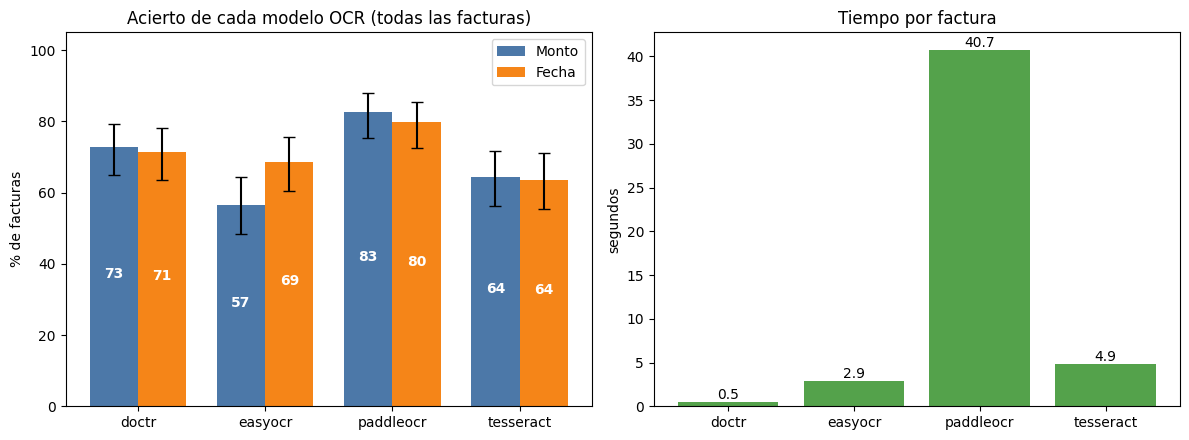

Casos donde algún modelo falló en monto o fecha: 280 (se muestran los primeros 15)


,motor,foto,monto_real,monto_leido,fecha_real,fecha_leida
1,tesseract,factura_002_1.jpeg,97000.0,1876410.00,2026-10-24,2020-10-24
2,tesseract,factura_003_1.jpg;factura_003_2.jpg,985694.0,985694.00,2026-06-15,2026-08-28
3,tesseract,factura_004_1.jpg,64000.0,504000.00,2026-10-15,2026-10-16
4,tesseract,factura_005_1.jpg,93200.0,3370000.00,2026-10-06,2026-10-06
5,tesseract,factura_006_1.jpg,90910.0,7020430.00,2026-03-22,None
6,tesseract,factura_007_1.jpg,195720.0,6452504.00,2026-09-07,None
7,tesseract,factura_008_1.jpg,699400.0,867794.09,2022-11-13,2022-11-19
8,tesseract,factura_009_1.jpg,70450.0,70108.00,2025-05-19,2025-05-19
11,tesseract,factura_012_1.jpeg,46300.0,42870.00,2026-10-26,2026-10-26
13,tesseract,factura_014_1.jpeg,44900.0,44900.00,2026-10-26,2026-09-09


In [ ]:
def wilson(aciertos, n, z=1.96):
    if n == 0:
        return (0.0, 0.0)
    p = aciertos / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    m = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (max(0, c - m) * 100, min(1, c + m) * 100)

def resumen(d):
    t = d.groupby("motor").agg(facturas=("foto", "count"),
                               monto_ok=("monto_ok", "mean"), monto_en_texto=("monto_en_texto", "mean"),
                               fecha_ok=("fecha_ok", "mean"), fecha_en_texto=("fecha_en_texto", "mean"),
                               segundos_por_factura=("segundos", "mean"))
    for c in ["monto_ok", "monto_en_texto", "fecha_ok", "fecha_en_texto"]:
        t[c] = (t[c] * 100).round(1)
    t["segundos_por_factura"] = t["segundos_por_factura"].round(2)
    t["dispositivo"] = [INFO.get(m, {}).get("dispositivo", "?") for m in t.index]
    return t

tabla_todas = resumen(res)
tabla_prueba = resumen(res[res["split"] == "prueba"])
print("Todas las facturas (porcentajes):")
display(tabla_todas)
print("Solo facturas de prueba (porcentajes):")
display(tabla_prueba)

orden = tabla_todas.index.tolist()
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
x = np.arange(len(orden))
ancho = 0.38
for k, (col, color, nombre) in enumerate([("monto_ok", "#4C78A8", "Monto"), ("fecha_ok", "#F58518", "Fecha")]):
    vals, bajo, alto = [], [], []
    for m in orden:
        d = res[res["motor"] == m]
        n, a = len(d), int(d[col].sum())
        lo, hi = wilson(a, n)
        vals.append(a / n * 100)
        bajo.append(a / n * 100 - lo)
        alto.append(hi - a / n * 100)
    barras = ejes[0].bar(x + (k - 0.5) * ancho, vals, ancho, color=color, label=nombre,
                         yerr=[bajo, alto], capsize=4, ecolor="black")
    ejes[0].bar_label(barras, fmt="%.0f", padding=2, label_type="center", color="white", fontweight="bold")
ejes[0].set_xticks(x)
ejes[0].set_xticklabels(orden)
ejes[0].set_ylim(0, 105)
ejes[0].set_ylabel("% de facturas")
ejes[0].set_title("Acierto de cada modelo OCR (todas las facturas)")
ejes[0].legend()
b = ejes[1].bar(orden, tabla_todas.loc[orden, "segundos_por_factura"], color="#54A24B")
ejes[1].bar_label(b, fmt="%.1f")
ejes[1].set_title("Tiempo por factura")
ejes[1].set_ylabel("segundos")
plt.tight_layout()
plt.savefig(os.path.join(RESULTADOS, "grafica_ocr.png"), dpi=150)
plt.show()

errores = res[(~res["monto_ok"]) | (~res["fecha_ok"])][["motor", "foto", "monto_real", "monto_leido", "fecha_real", "fecha_leida"]]
print(f"Casos donde algún modelo falló en monto o fecha: {len(errores)} (se muestran los primeros 15)")
display(errores.head(15))

**Cómo leer la tabla**
- `monto_en_texto` y `fecha_en_texto`: el OCR **sí leyó** ese valor en algún lugar de la factura. Mide qué tan bien lee el modelo.
- `monto_ok` y `fecha_ok`: además, la regla **escogió** el valor correcto. Depende del OCR y de la regla.
- Si `en_texto` es alto pero `ok` es bajo, el modelo lee bien y lo que hay que mejorar es la regla.
- `dispositivo`: los tiempos en GPU y en CPU no se pueden comparar directamente.
- Si ajustas las reglas mirando errores, hazlo solo con facturas de entrenamiento y reporta la tabla de prueba.

## 10. Clasificador de categoría
Con el texto que leyó cada OCR se entrena un clasificador que adivina la categoría de la factura. Se comparan tres:
- **k-NN** (k vecinos más cercanos, como en el Colab 8 del curso): la factura toma la categoría de las facturas más parecidas.
- **Regresión logística.**
- **Naive Bayes.**

El texto se convierte en números con **TF-IDF de pedacitos de letras** (2 a 4 letras): así aguanta mejor los errores de lectura del OCR (por ejemplo, “T0TAL” en vez de “TOTAL”).

Punto de partida sin IA: decir siempre 'Supermercado' acierta 22.2% en la prueba



,motor_ocr,clasificador,exactitud_entrenamiento,exactitud_prueba,f1_macro_prueba,f1_macro_validacion_cruzada
0,tesseract,k-NN (k=5),100.0,69.4,52.2,57.0
1,tesseract,Regresión logística,99.1,80.6,73.4,59.0
2,tesseract,Naive Bayes,54.2,41.7,20.2,20.2
3,easyocr,k-NN (k=5),100.0,75.0,66.0,61.1
4,easyocr,Regresión logística,99.1,83.3,74.2,60.5
5,easyocr,Naive Bayes,55.1,41.7,20.2,22.7
6,doctr,k-NN (k=5),100.0,77.8,68.9,58.4
7,doctr,Regresión logística,98.1,83.3,76.9,68.4
8,doctr,Naive Bayes,56.1,41.7,20.2,23.7
9,paddleocr,k-NN (k=5),100.0,77.8,67.6,60.4


Con pocas facturas de prueba, un solo acierto mueve mucho el porcentaje: mira también la validación cruzada (se calcula solo con entrenamiento).

Diagnóstico (entrenamiento vs prueba):
- tesseract + k-NN (k=5): entrenamiento 100% · prueba 69% → posible sobreajuste: le va mucho mejor con lo que ya vio que con facturas nuevas
- tesseract + Regresión logística: entrenamiento 99% · prueba 81% → generaliza bien: la nota con facturas nuevas se parece a la de entrenamiento
- tesseract + Naive Bayes: entrenamiento 54% · prueba 42% → subajuste: ni siquiera aprende bien lo que ya vio
- easyocr + k-NN (k=5): entrenamiento 100% · prueba 75% → posible sobreajuste: le va mucho mejor con lo que ya vio que con facturas nuevas
- easyocr + Regresión logística: entrenamiento 99% · prueba 83% → generaliza bien: la nota con facturas nuevas se parece a la de entrenamiento
- easyocr + Naive Bayes: entrenamiento 55% · prueba 42% → subajuste: ni siquiera aprende bien lo que ya vio
- doctr + k-NN (k=5): entrena

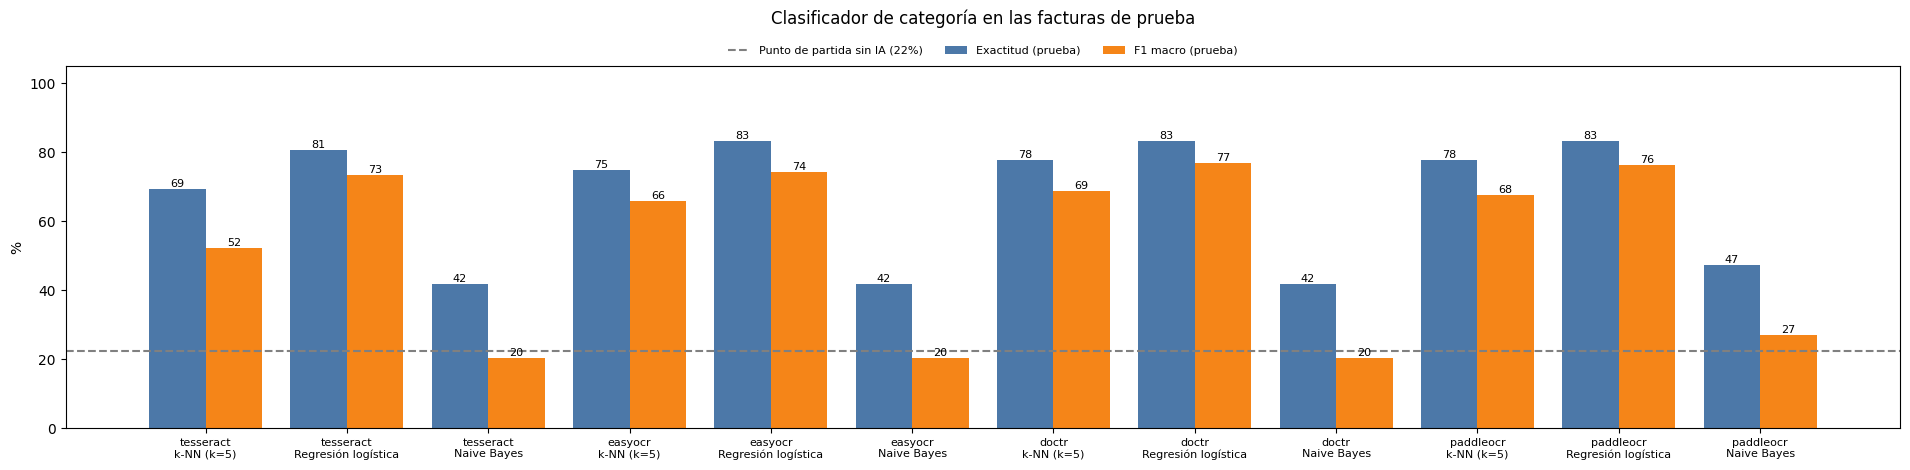

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score

def armar(clf):
    return make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), strip_accents="unicode",
                                         lowercase=True, sublinear_tf=True), clf)

CLASIFICADORES = {
    "k-NN (k=5)": lambda: armar(KNeighborsClassifier(n_neighbors=5, metric="cosine", weights="distance")),
    "Regresión logística": lambda: armar(LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Naive Bayes": lambda: armar(MultinomialNB()),
}

es_train = (df["split"] == "entrenamiento").values
es_test = (df["split"] == "prueba").values
y = df["categoria"].values
mayoritaria = pd.Series(y[es_train]).mode()[0]
base = accuracy_score(y[es_test], [mayoritaria] * es_test.sum())
print(f"Punto de partida sin IA: decir siempre '{mayoritaria}' acierta {base * 100:.1f}% en la prueba\n")

min_clase = int(pd.Series(y[es_train]).value_counts().min())
pliegues = max(2, min(5, min_clase))

filas, PRED = [], {}
for motor in textos:
    X = np.array(textos[motor], dtype=object)
    if sum(len(t.strip()) > 0 for t in X) < 10:
        print(f"{motor}: casi no leyó texto, se omite")
        continue
    for nombre, fabrica in CLASIFICADORES.items():
        m = fabrica().fit(X[es_train], y[es_train])
        pred = m.predict(X[es_test])
        try:
            cv = cross_val_score(fabrica(), X[es_train], y[es_train], scoring="f1_macro",
                                 cv=StratifiedKFold(pliegues, shuffle=True, random_state=SEMILLA)).mean()
        except Exception:
            cv = np.nan
        f1 = f1_score(y[es_test], pred, average="macro", zero_division=0)
        acc_train = accuracy_score(y[es_train], m.predict(X[es_train]))
        filas.append({"motor_ocr": motor, "clasificador": nombre,
                      "exactitud_entrenamiento": round(acc_train * 100, 1),
                      "exactitud_prueba": round(accuracy_score(y[es_test], pred) * 100, 1),
                      "f1_macro_prueba": round(f1 * 100, 1),
                      "f1_macro_validacion_cruzada": round(cv * 100, 1) if cv == cv else None})
        PRED[(motor, nombre)] = {"f1": f1, "cv": cv, "pred": pred}

clasif = pd.DataFrame(filas)
display(clasif)
print("Con pocas facturas de prueba, un solo acierto mueve mucho el porcentaje: mira también la validación cruzada (se calcula solo con entrenamiento).")

# ¿Sobreajuste o subajuste? Se compara la nota con las facturas que el modelo YA vio (entrenamiento)
# contra la nota con facturas NUEVAS (prueba).
print("\nDiagnóstico (entrenamiento vs prueba):")
for _, f_ in clasif.iterrows():
    brecha = f_["exactitud_entrenamiento"] - f_["exactitud_prueba"]
    if f_["exactitud_entrenamiento"] < 60:
        dx = "subajuste: ni siquiera aprende bien lo que ya vio"
    elif brecha > 20:
        dx = "posible sobreajuste: le va mucho mejor con lo que ya vio que con facturas nuevas"
    else:
        dx = "generaliza bien: la nota con facturas nuevas se parece a la de entrenamiento"
    print(f"- {f_['motor_ocr']} + {f_['clasificador']}: entrenamiento {f_['exactitud_entrenamiento']:.0f}% · prueba {f_['exactitud_prueba']:.0f}% → {dx}")

etq = (clasif["motor_ocr"] + "\n" + clasif["clasificador"]).tolist()
x = np.arange(len(clasif))
fig, ax = plt.subplots(figsize=(max(8, 1.6 * len(clasif)), 4.8))
b1 = ax.bar(x - 0.2, clasif["exactitud_prueba"], 0.4, label="Exactitud (prueba)", color="#4C78A8")
b2 = ax.bar(x + 0.2, clasif["f1_macro_prueba"], 0.4, label="F1 macro (prueba)", color="#F58518")
ax.axhline(base * 100, color="gray", linestyle="--", label=f"Punto de partida sin IA ({base * 100:.0f}%)")
ax.bar_label(b1, fmt="%.0f", fontsize=8)
ax.bar_label(b2, fmt="%.0f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(etq, fontsize=8)
ax.set_ylim(0, 105)
ax.set_ylabel("%")
ax.set_title("Clasificador de categoría en las facturas de prueba", pad=30)
ax.legend(ncol=3, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(RESULTADOS, "grafica_clasificador.png"), dpi=150)
plt.show()

Mejor combinación: OCR = doctr, clasificador = Regresión logística

                           precision    recall  f1-score   support

                Educación       1.00      1.00      1.00         2
          Entretenimiento       0.80      1.00      0.89         4
                    Hogar       1.00      1.00      1.00         1
                    Otros       0.40      0.67      0.50         3
Restaurantes y domicilios       1.00      0.67      0.80         3
        Ropa y accesorios       0.00      0.00      0.00         1
                    Salud       0.67      0.67      0.67         3
                Servicios       1.00      1.00      1.00         4
             Supermercado       1.00      1.00      1.00         8
               Transporte       1.00      0.71      0.83         7

                 accuracy                           0.83        36
                macro avg       0.79      0.77      0.77        36
             weighted avg       0.87      0.83      0.84   

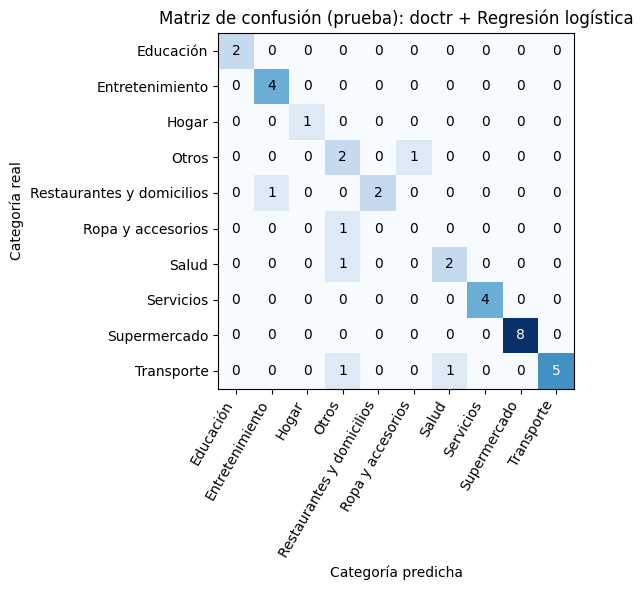

In [ ]:
# Detalle por categoría y matriz de confusión del mejor caso.
# Se escoge por validación cruzada (solo entrenamiento) para no "hacer trampa" mirando la prueba.
(motor_top, clf_top), mejor = max(PRED.items(), key=lambda kv: (np.nan_to_num(kv[1]["cv"], nan=-1), kv[1]["f1"]))
pred_top = mejor["pred"]
print(f"Mejor combinación: OCR = {motor_top}, clasificador = {clf_top}\n")
print(classification_report(y[es_test], pred_top, zero_division=0))

etiquetas = sorted(set(y[es_test]) | set(pred_top))
cm = confusion_matrix(y[es_test], pred_top, labels=etiquetas)
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(etiquetas)))
ax.set_yticks(range(len(etiquetas)))
ax.set_xticklabels(etiquetas, rotation=60, ha="right")
ax.set_yticklabels(etiquetas)
for i in range(len(etiquetas)):
    for j in range(len(etiquetas)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Categoría predicha")
ax.set_ylabel("Categoría real")
ax.set_title(f"Matriz de confusión (prueba): {motor_top} + {clf_top}")
plt.tight_layout()
plt.savefig(os.path.join(RESULTADOS, "matriz_confusion.png"), dpi=150)
plt.show()

## 10b. Motivo sugerido
El motivo es **texto libre**: una persona escribe "Gasolina" y otra "Tanqueada del carro para el viaje". Por eso no se puede pedir que Dai lo escriba **igual**; se le pide que proponga un motivo **que el usuario acepte sin reescribirlo**.

**Cómo lo propone Dai (k-NN con k = 1):** busca, entre las facturas de entrenamiento, la que más se parece en texto a la factura nueva y le sugiere **el motivo que escribió esa persona**, recortado a **50 caracteres** (el límite de la app). Una factura de gas Vanti recibe el motivo de otra factura de gas; un tiquete de DiDi, el de otro DiDi.

**Cómo se califica:** el motivo sugerido es aceptable si comparte **al menos una palabra clave** con el motivo real. Antes de comparar se pasa a minúsculas, se quitan tildes, se ignoran palabras vacías ("de", "la", "compra", "factura", los meses...) y cada palabra se recorta a 5 letras para que "gasolina" y "gasolinas" cuenten igual.

Ejemplos: "Gasolina" vs "Gasolina del carro" → **sí**. "Compra de mercado" vs "Compra de suministros" → **no** ("compra" no cuenta).

**Punto de partida sin IA:** usar como motivo el nombre de la categoría ("Transporte"). Si Dai no supera eso, no sirve.

In [ ]:
from sklearn.neighbors import NearestNeighbors

LIMITE_MOTIVO = 50
VACIAS = set(("de del la las el los y en para por con a al mes un una su sus mi mis factura compra compras pago "
              "valor total enero febrero marzo abril mayo junio julio agosto septiembre setiembre octubre "
              "noviembre diciembre").split())

def claves(texto):
    t = sin_tildes(str(texto).lower())
    return {w[:5] for w in re.findall(r"[a-zñ]+", t) if len(w) >= 3 and w not in VACIAS}

def motivo_aceptable(sugerido, real):
    return len(claves(sugerido) & claves(real)) > 0

motivos_reales = df["motivo"].fillna("").astype(str).values
base_motivo = np.mean([motivo_aceptable(c, m) for c, m in zip(y[es_test], motivos_reales[es_test])])
print(f"Punto de partida sin IA (usar el nombre de la categoría): {base_motivo * 100:.1f}% aceptables\n")

MOTIVO_OK, filas_m, ejemplos = {}, [], []
for motor in textos:
    X = np.array(textos[motor], dtype=object)
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), strip_accents="unicode", lowercase=True, sublinear_tf=True)
    Xtr = vec.fit_transform(X[es_train])
    vecino = NearestNeighbors(n_neighbors=1, metric="cosine").fit(Xtr)
    _, idx = vecino.kneighbors(vec.transform(X[es_test]))
    sugeridos = [m.strip()[:LIMITE_MOTIVO] for m in motivos_reales[es_train][idx[:, 0]]]
    ok = np.array([motivo_aceptable(s_, r_) for s_, r_ in zip(sugeridos, motivos_reales[es_test])])
    MOTIVO_OK[motor] = pd.Series(ok, index=df.index[es_test])
    lo, hi = wilson(int(ok.sum()), len(ok))
    filas_m.append({"motor_ocr": motor, "motivo_aceptable_%": round(ok.mean() * 100, 1), "IC95": f"{lo:.0f}–{hi:.0f}"})
    for s_, r_, o_ in zip(sugeridos, motivos_reales[es_test], ok):
        ejemplos.append({"motor_ocr": motor, "motivo_sugerido": s_, "motivo_real": r_, "aceptable": bool(o_)})

tabla_motivo = pd.DataFrame(filas_m).sort_values("motivo_aceptable_%", ascending=False)
ejemplos_motivo = pd.DataFrame(ejemplos)
display(tabla_motivo)
print("Ejemplos con el primer modelo de la tabla:")
display(ejemplos_motivo[ejemplos_motivo["motor_ocr"] == tabla_motivo.iloc[0]["motor_ocr"]].head(10))

Punto de partida sin IA (usar el nombre de la categoría): 5.6% aceptables



,motor_ocr,motivo_aceptable_%,IC95
3,paddleocr,72.2,56–84
2,doctr,72.2,56–84
1,easyocr,66.7,50–80
0,tesseract,61.1,45–75


Ejemplos con el primer modelo de la tabla:


,motor_ocr,motivo_sugerido,motivo_real,aceptable
108,paddleocr,Pension Agosto 2026,Compra de piedras decorativas para ropa,False
109,paddleocr,Gasolina,Gasolina del carro,True
110,paddleocr,gasolina,Viaje de graduación,False
111,paddleocr,Compra de prendas de vestir,Salud de mascotas,False
112,paddleocr,Compra gustos personales,Waffle con helado,False
113,paddleocr,Hamburguesa,Hamburguesa,True
114,paddleocr,Compra gustos personales,Compra de medicamentos para la garganta,False
115,paddleocr,Gastos Personales,Compra de pizzas grandes y más comida,False
116,paddleocr,Gustos de compras personales,gastos personales,True
117,paddleocr,Compra gustos personales,implementos personales,True


## 11. Decisión: ¿qué modelo usamos para Dai?
La gráfica pone **los 4 campos** que Dai llena en la pantalla "Confirmar" (monto, fecha, categoría y motivo) para cada modelo, todo medido en las mismas facturas de prueba.

La métrica principal es la del proyecto: **% de facturas que el usuario no tendría que corregir**, es decir, facturas de prueba con **los 4 campos bien a la vez**. La tabla también muestra cuántas quedan bien en los 3 campos exactos (monto, fecha y categoría), sin contar el motivo.

Para cada OCR se usa el clasificador con mejor validación cruzada (calculada solo con entrenamiento), así la decisión no se toma mirando la prueba.

,modelo_ocr,clasificador,monto_ok_%,fecha_ok_%,categoria_ok_%,motivo_ok_%,sin_correccion_%,IC95_sin_correccion,monto_fecha_categoria_%,seg_por_factura,dispositivo
0,paddleocr,Regresión logística,83.3,83.3,83.3,72.2,52.8,37–68,63.9,42.25,CPU
1,easyocr,k-NN (k=5),55.6,69.4,75.0,66.7,30.6,18–47,41.7,3.16,GPU
2,tesseract,Regresión logística,63.9,69.4,80.6,61.1,27.8,16–44,44.4,4.76,CPU (idioma eng)
3,doctr,Regresión logística,72.2,63.9,83.3,72.2,25.0,14–41,33.3,0.50,GPU


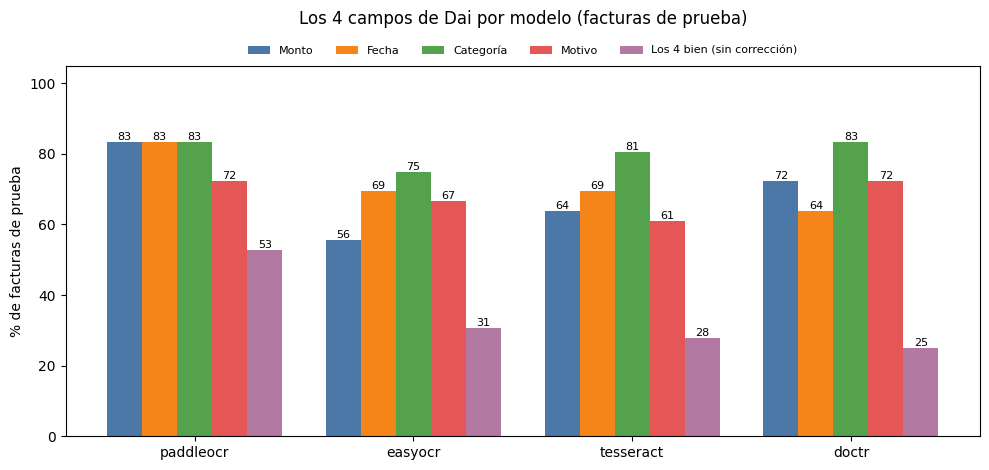

Modelo recomendado: paddleocr (con Regresión logística para la categoría).
En las facturas de prueba, 53% quedarían sin corrección (intervalo de confianza del 95%: 37–68%).
Segundo lugar: easyocr con 31% (IC95%: 18–47%).
Si los intervalos de los dos primeros se cruzan, la diferencia puede ser azar: en ese caso pesan también el tiempo y si el modelo puede correr dentro de la app.

Por qué no los otros modelos:
- easyocr: 31% sin corrección; acierta 28 puntos menos en monto, acierta 14 puntos menos en fecha, acierta 8 puntos menos en categoría, acierta 6 puntos menos en motivo.
- tesseract: 28% sin corrección; acierta 19 puntos menos en monto, acierta 14 puntos menos en fecha, acierta 3 puntos menos en categoría, acierta 11 puntos menos en motivo.
- doctr: 25% sin corrección; acierta 11 puntos menos en monto, acierta 19 puntos menos en fecha.


In [ ]:
filas = []
prueba = res[res["split"] == "prueba"]
for motor in textos:
    opciones = {n: v for (m, n), v in PRED.items() if m == motor}
    if not opciones:
        continue
    clf_m = max(opciones, key=lambda n: (np.nan_to_num(opciones[n]["cv"], nan=-1), opciones[n]["f1"]))
    cat_ok = pd.Series(opciones[clf_m]["pred"] == y[es_test], index=df.index[es_test])
    p = prueba[prueba["motor"] == motor].set_index("id")
    mot_ok = MOTIVO_OK[motor].reindex(p.index).fillna(False)
    tres_ok = p["monto_ok"] & p["fecha_ok"] & cat_ok.reindex(p.index).fillna(False)
    todo_ok = tres_ok & mot_ok
    n = len(p)
    lo, hi = wilson(int(todo_ok.sum()), n)
    filas.append({"modelo_ocr": motor, "clasificador": clf_m,
                  "monto_ok_%": round(p["monto_ok"].mean() * 100, 1),
                  "fecha_ok_%": round(p["fecha_ok"].mean() * 100, 1),
                  "categoria_ok_%": round(cat_ok.mean() * 100, 1),
                  "motivo_ok_%": round(mot_ok.mean() * 100, 1),
                  "sin_correccion_%": round(todo_ok.mean() * 100, 1),
                  "IC95_sin_correccion": f"{lo:.0f}–{hi:.0f}",
                  "monto_fecha_categoria_%": round(tres_ok.mean() * 100, 1),
                  "seg_por_factura": round(p["segundos"].mean(), 2),
                  "dispositivo": INFO.get(motor, {}).get("dispositivo", "?")})
decision = pd.DataFrame(filas).sort_values(["sin_correccion_%", "monto_ok_%"], ascending=False).reset_index(drop=True)
display(decision)

fig, ax = plt.subplots(figsize=(10, 4.8))
cols = ["monto_ok_%", "fecha_ok_%", "categoria_ok_%", "motivo_ok_%", "sin_correccion_%"]
nombres = ["Monto", "Fecha", "Categoría", "Motivo", "Los 4 bien (sin corrección)"]
colores = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#B279A2"]
x = np.arange(len(decision))
for k, (c, n, col) in enumerate(zip(cols, nombres, colores)):
    b = ax.bar(x + (k - 2) * 0.16, decision[c], 0.16, label=n, color=col)
    ax.bar_label(b, fmt="%.0f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(decision["modelo_ocr"])
ax.set_ylim(0, 105)
ax.set_ylabel("% de facturas de prueba")
ax.set_title("Los 4 campos de Dai por modelo (facturas de prueba)", pad=30)
ax.legend(ncol=5, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(RESULTADOS, "grafica_decision.png"), dpi=150)
plt.show()

g = decision.iloc[0]
print(f"Modelo recomendado: {g['modelo_ocr']} (con {g['clasificador']} para la categoría).")
print(f"En las facturas de prueba, {g['sin_correccion_%']:.0f}% quedarían sin corrección "
      f"(intervalo de confianza del 95%: {g['IC95_sin_correccion']}%).")
if len(decision) > 1:
    s = decision.iloc[1]
    print(f"Segundo lugar: {s['modelo_ocr']} con {s['sin_correccion_%']:.0f}% (IC95%: {s['IC95_sin_correccion']}%).")
    print("Si los intervalos de los dos primeros se cruzan, la diferencia puede ser azar: en ese caso pesan también el tiempo y si el modelo puede correr dentro de la app.")

# Frases listas para la sustentación: por qué este sí y por qué los otros no
print("\nPor qué no los otros modelos:")
for _, o in decision.iloc[1:].iterrows():
    razones = []
    for c, nombre in [("monto_ok_%", "monto"), ("fecha_ok_%", "fecha"), ("categoria_ok_%", "categoría"), ("motivo_ok_%", "motivo")]:
        dif = g[c] - o[c]
        if dif > 0:
            razones.append(f"acierta {dif:.0f} puntos menos en {nombre}")
    if o["seg_por_factura"] > 1.5 * g["seg_por_factura"]:
        razones.append(f"es {o['seg_por_factura'] / max(g['seg_por_factura'], 0.01):.1f} veces más lento")
    if not razones:
        razones.append("empata con el ganador; se prefiere el ganador por tiempo o por facilidad de uso")
    print(f"- {o['modelo_ocr']}: {o['sin_correccion_%']:.0f}% sin corrección; " + ", ".join(razones) + ".")

## 12. Guardar los resultados
Todo lo importante ya se ve arriba. Esta celda guarda las tablas, los textos que leyó cada OCR y las gráficas en la carpeta de resultados (en Drive, si lo activaste) y arma un zip.

In [ ]:
DESCARGAR_ZIP = True  # True = además descarga el zip a tu computador
res.to_csv(os.path.join(RESULTADOS, "resultados_por_factura.csv"), index=False, encoding="utf-8")
tabla_todas.to_csv(os.path.join(RESULTADOS, "ocr_resumen_todas.csv"), encoding="utf-8")
tabla_prueba.to_csv(os.path.join(RESULTADOS, "ocr_resumen_prueba.csv"), encoding="utf-8")
clasif.to_csv(os.path.join(RESULTADOS, "clasificador_resumen.csv"), index=False, encoding="utf-8")
decision.to_csv(os.path.join(RESULTADOS, "tabla_decision.csv"), index=False, encoding="utf-8")
tabla_motivo.to_csv(os.path.join(RESULTADOS, "motivo_resumen.csv"), index=False, encoding="utf-8")
ejemplos_motivo.to_csv(os.path.join(RESULTADOS, "motivo_ejemplos.csv"), index=False, encoding="utf-8")
df[["foto", "categoria", "split"]].to_csv(os.path.join(RESULTADOS, "split.csv"), index=False, encoding="utf-8")
with open(os.path.join(RESULTADOS, "textos_ocr.json"), "w", encoding="utf-8") as f:
    json.dump(textos, f, ensure_ascii=False)
zip_salida = shutil.make_archive(os.path.join(LOCAL, "resultados_ocr"), "zip", RESULTADOS)
print("Resultados guardados en:", RESULTADOS)
if EN_COLAB and DESCARGAR_ZIP:
    files.download(zip_salida)

Resultados guardados en: /content/drive/MyDrive/comparacion_ocr_facturas/resultados


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>